### 1. Tahap Data Loading (Pemuatan Data)
Pada tahap ini, kita memuat dataset mentah dari file eksternal berformat CSV (`salary_prediction_data.csv`) ke dalam memori menggunakan pustaka `pandas`. Langkah ini bertujuan untuk memeriksa struktur awal tabel, melihat 5 baris pertama data, serta memverifikasi tipe data dan jumlah total baris/kolom pada dataset.

In [1]:
import pandas as pd
import numpy as np

# 1. Memuat dataset dari file CSV
df = pd.read_csv("salary_prediction_data.csv")

# 2. Menampilkan 5 baris pertama dataset
print("--- 5 Baris Pertama Data ---")
display(df.head())

# 3. Menampilkan informasi struktur dataset
print("\n--- Informasi Dataset ---")
df.info()

--- 5 Baris Pertama Data ---


,Education,Experience,Location,Job_Title,Age,Gender,Salary
0,High School,8,Urban,Manager,63,Male,84620.053665
1,PhD,11,Suburban,Director,59,Male,142591.255894
2,Bachelor,28,Suburban,Manager,61,Female,97800.255404
3,High School,29,Rural,Director,45,Male,96834.671282
4,PhD,25,Urban,Analyst,26,Female,132157.786175



--- Informasi Dataset ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Education   1000 non-null   str    
 1   Experience  1000 non-null   int64  
 2   Location    1000 non-null   str    
 3   Job_Title   1000 non-null   str    
 4   Age         1000 non-null   int64  
 5   Gender      1000 non-null   str    
 6   Salary      1000 non-null   float64
dtypes: float64(1), int64(2), str(4)
memory usage: 54.8 KB


### 2. Tahap Data Cleaning (Pembersihan Data)
Pada tahap ini, kita melakukan pemeriksaan terhadap kualitas data, meliputi pengecekan nilai yang hilang (*missing values*) serta identifikasi baris data ganda (*duplicate rows*) agar model tidak mengalami bias.

In [2]:
# 1. Pengecekan missing values per kolom
print("--- Pengecekan Missing Values per Kolom ---")
print(df.isnull().sum())

# 2. Pengecekan dan penanganan baris duplikat
print(f"\nJumlah baris duplikat sebelum dibersihkan: {df.duplicated().sum()}")
df = df.drop_duplicates()

# 3. Menampilkan total baris setelah pembersihan
print(f"Jumlah baris data setelah pembersihan: {len(df)}")

--- Pengecekan Missing Values per Kolom ---
Education     0
Experience    0
Location      0
Job_Title     0
Age           0
Gender        0
Salary        0
dtype: int64

Jumlah baris duplikat sebelum dibersihkan: 0
Jumlah baris data setelah pembersihan: 1000


### 3. Tahap Data Transformation & Label Encoding
Sebagian besar algoritma *machine learning* membutuhkan masukan dalam bentuk angka. Pada tahap ini, fitur-fitur kategorikal bertipe teks diubah menjadi format numerik menggunakan teknik *Label Encoding*.

In [3]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# 1. Membuat salinan dataframe dari data asli (df)
df_encoded = df.copy()
le = LabelEncoder()

# 2. Melakukan Label Encoding untuk kolom teks/kategorikal
categorical_cols = df_encoded.select_dtypes(include=['object', 'string']).columns
for col in categorical_cols:
    df_encoded[col] = le.fit_transform(df_encoded[col])

print("--- Berhasil melakukan Label Encoding ---")

# 3. Melakukan Standarisasi (Feature Scaling) menggunakan StandardScaler
scaler = StandardScaler()
numeric_cols = df_encoded.drop(columns=['Salary']).select_dtypes(include=['int64', 'float64']).columns

df_scaled = df_encoded.copy()
df_scaled[numeric_cols] = scaler.fit_transform(df_encoded[numeric_cols])

print("--- Berhasil melakukan Standarisasi (Feature Scaling) ---")
display(df_scaled.head())

--- Berhasil melakukan Label Encoding ---
--- Berhasil melakukan Standarisasi (Feature Scaling) ---


,Education,Experience,Location,Job_Title,Age,Gender,Salary
0,-0.436891,-0.812169,1.280048,1.386517,1.516107,0.968496,84620.053665
1,1.346337,-0.452324,0.043287,-0.409490,1.222045,0.968496,142591.255894
2,-1.328505,1.586793,0.043287,1.386517,1.369076,-1.032529,97800.255404
3,-0.436891,1.706741,-1.193475,-0.409490,0.192831,0.968496,96834.671282
4,1.346337,1.226949,1.280048,-1.307493,-1.203961,-1.032529,132157.786175


### 4. Tahap Penanganan Outlier (IQR Method)
Nilai pencilan (*outlier*) yang terlalu ekstrim pada data dapat mempengaruhi performa model regresi. Pada tahap ini, kita mendeteksi dan menyaring *outlier* pada kolom target (`Salary`) menggunakan metode *Interquartile Range* (IQR).

In [4]:
# Menghitung Q1 (kuartil 25) dan Q3 (kuartil 75) dari kolom Salary
Q1 = df_encoded['Salary'].quantile(0.25)
Q3 = df_encoded['Salary'].quantile(0.75)
IQR = Q3 - Q1

# Menentukan batas bawah dan batas atas untuk outlier
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Menyaring dataframe agar hanya berisi data di dalam batas wajar
df_clean = df_encoded[(df_encoded['Salary'] >= lower_bound) & (df_encoded['Salary'] <= upper_bound)]

print(f"Jumlah baris sebelum pembersihan outlier: {len(df_encoded)}")
print(f"Jumlah baris setelah pembersihan outlier: {len(df_clean)}")

Jumlah baris sebelum pembersihan outlier: 1000
Jumlah baris setelah pembersihan outlier: 999


### visualisasi outliers

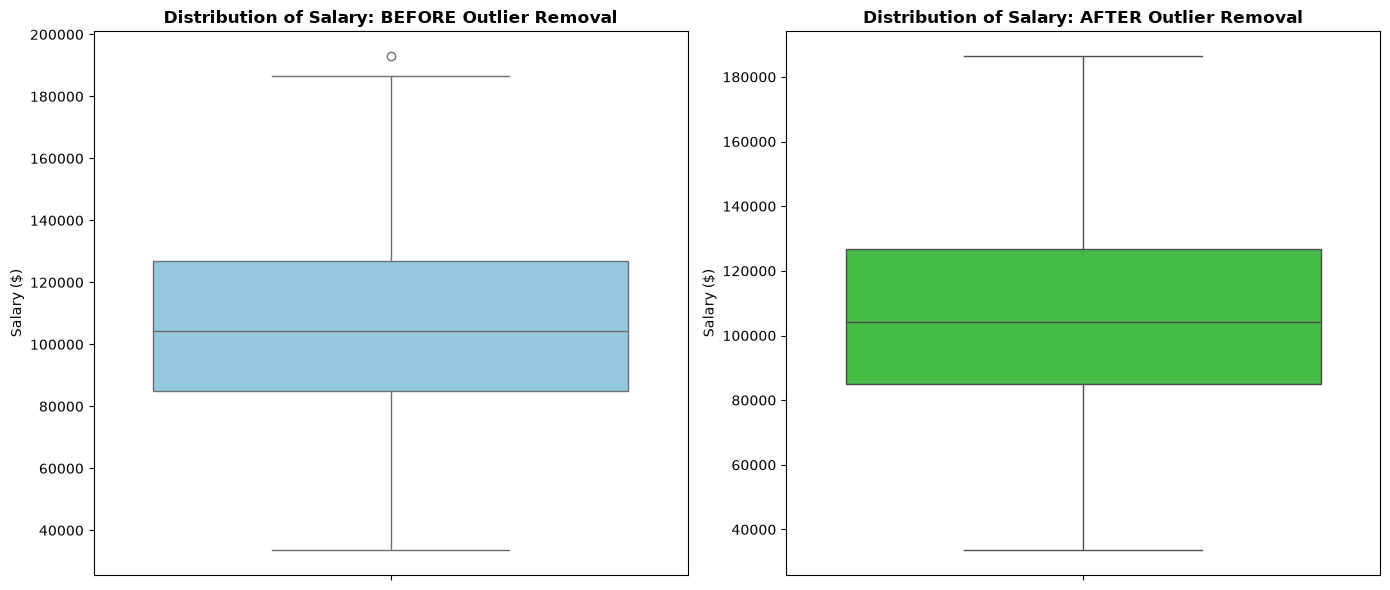

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat canvas dengan 2 kolom grafik berdampingan
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Grafik Sebelah Kiri: SEBELUM Pembersihan Outlier
sns.boxplot(y=df_encoded['Salary'], ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Salary: BEFORE Outlier Removal', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Salary ($)', fontsize=10)

# 2. Grafik Sebelah Kanan: SESUDAH Pembersihan Outlier
sns.boxplot(y=df_clean['Salary'], ax=axes[1], color='limegreen')
axes[1].set_title('Distribution of Salary: AFTER Outlier Removal', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Salary ($)', fontsize=10)

# Menyesuaikan tata letak agar rapi
plt.tight_layout()

# Menampilkan grafik
plt.show()

### 5. Tahap Exploratory Data Analysis (EDA)
EDA dilakukan untuk memahami karakteristik dan sebaran data melalui statistik deskriptif serta visualisasi matriks korelasi menggunakan `Matplotlib` dan `Seaborn`.

--- Statistik Deskriptif ---


,Education,Experience,Location,Job_Title,Age,Gender,Salary
count,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000
mean,1.488488,14.765766,0.964965,1.456456,42.366366,0.516517,105470.858495
std,1.121666,8.343646,0.809373,1.114603,13.612071,0.499977,28135.113125
min,0.000000,1.000000,0.000000,0.000000,20.000000,0.000000,33510.510669
25%,0.000000,7.000000,0.000000,0.000000,30.000000,0.000000,84985.242218
50%,1.000000,15.000000,1.000000,1.000000,43.000000,1.000000,104313.191044
75%,2.500000,22.000000,2.000000,2.000000,55.000000,1.000000,126627.060063
max,3.000000,29.000000,2.000000,3.000000,64.000000,1.000000,186452.845727


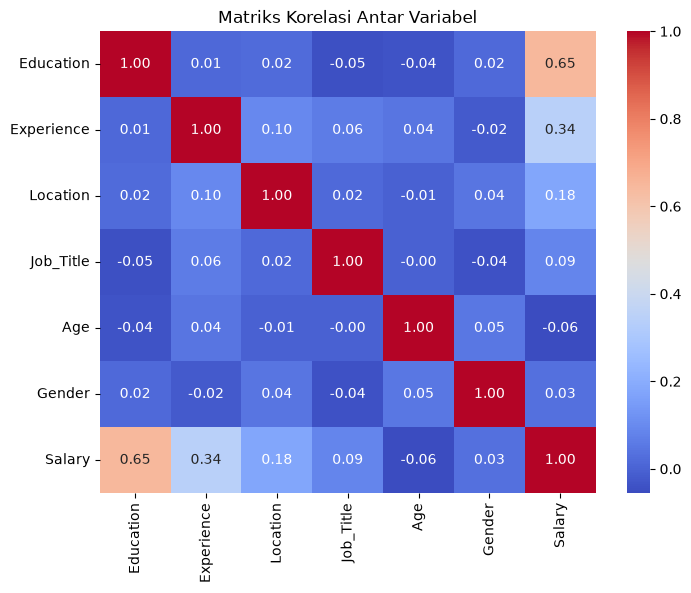

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Menampilkan Statistik Deskriptif
print("--- Statistik Deskriptif ---")
display(df_clean.describe())

# 2. Visualisasi Matriks Korelasi (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi Antar Variabel')
plt.show()

### 6. Tahap Data Splitting (Pembagian Data)
Dataset dipisahkan menjadi matriks fitur (X) dan vektor target (y). Selanjutnya, data dibagi menjadi data latih (*training set*) dan data uji (*testing set*) dengan rasio 80:20.

In [7]:
from sklearn.model_selection import train_test_split

# 1. Memisahkan Fitur (X) dan Target (y) dari data yang SUDAH BERSIH
X = df_clean.drop(columns=['Salary'])
y = df_clean['Salary']

# 2. Membagi data (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("--- Hasil Data Splitting ---")
print(f"Jumlah Data Latih (X_train) : {len(X_train)} baris")
print(f"Jumlah Data Uji (X_test)    : {len(X_test)} baris")

--- Hasil Data Splitting ---
Jumlah Data Latih (X_train) : 799 baris
Jumlah Data Uji (X_test)    : 200 baris


### 7. Tahap Pembangunan & Pelatihan Model (Model Training)
Pada tahap ini, kita melatih data menggunakan tiga algoritma regresi yang berbeda tanpa *hyperparameter tuning*, yaitu *Least Angle Regression* (LARS), *Linear Regression*, dan *Gradient Boosting Regressor*, untuk melihat perbandingan performa dasarnya.

In [8]:
# 1. Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(X_train, y_train)

# 2. Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(X_train, y_train)

# 3. Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(X_train, y_train)

print("Status: Ketiga model berhasil dilatih!")

Status: Ketiga model berhasil dilatih!


### 8. Tahap Evaluasi Model (Model Evaluation)
Model dievaluasi menggunakan data uji (*validation set*) dengan metrik regresi berupa *Mean Absolute Error* (MAE), *Mean Squared Error* (MSE), dan *R-squared* ($R^2$). Hasil evaluasi dari ketiga model kemudian digabungkan ke dalam satu tabel ringkasan (*DataFrame*).

In [9]:
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Evaluasi Model LARS ---
pred_lars = lars.predict(X_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi awal
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}
df_results = pd.DataFrame(data, index=['Lars'])

# --- Evaluasi Model Linear Regression ---
pred_LR = LR.predict(X_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]

# --- Evaluasi Model Gradient Boosting Regressor ---
pred_GBR = GBR.predict(X_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]

# Menampilkan tabel hasil evaluasi
print("--- Tabel Perbandingan Performa Model ---")
display(df_results)

--- Tabel Perbandingan Performa Model ---


,MAE,MSE,R2
Lars,23308.336383,7.628752e+08,0.112231
Linear Regression,14982.778428,3.390086e+08,0.605491
GradientBoostingRegressor,8330.141885,1.058308e+08,0.876843


### 9. Tahap Menyimpan Model (Model Persistence)
Setelah model dilatih dan dievaluasi, model terbaik (dalam hal ini `GradientBoostingRegressor`) disimpan ke dalam bentuk *file* fisik menggunakan pustaka `joblib`. Hal ini memungkinkan model untuk dimuat kembali di masa mendatang (*deployment*) tanpa perlu melalui proses pelatihan ulang (*re-training*).

In [15]:
import json

# Mengambil 1 baris data dari X_test (atau data frame yang sudah di-encode)
# Pastikan menggunakan format array 2D
sample_input = X_test.iloc[[0]].values.tolist()

# Menyimpan ke file data.json yang sesuai dengan model 6 fitur
payload = {"data": sample_input}
with open("data.json", "w") as f:
    json.dump(payload, f)

print("File data.json berhasil dibuat dengan 6 fitur numerik yang valid!")
print("Isi data.json:", sample_input)

File data.json berhasil dibuat dengan 6 fitur numerik yang valid!
Isi data.json: [[1, 19, 0, 1, 31, 1]]


In [16]:
import joblib

# Menyimpan model GBR ke dalam file menggunakan joblib
joblib.dump(GBR, 'gbr_model.joblib')

print("Status: Model Gradient Boosting Regressor berhasil disimpan ke 'gbr_model.joblib'!")

Status: Model Gradient Boosting Regressor berhasil disimpan ke 'gbr_model.joblib'!


In [17]:
# Memuat model dari file joblib
joblib_model = joblib.load('gbr_model.joblib')

In [22]:
from flask import Flask, request, jsonify
import joblib

app = Flask(__name__)
joblib_model = joblib.load('gbr_model.joblib')

@app.route('/predict', methods=['POST'])
def predict():
    data = request.json['data']
    prediction = joblib_model.predict(data)
    return jsonify({'prediction': prediction.tolist()})

if __name__ == '__main__':
    app.run(host='127.0.0.1', port=5000, debug=True, use_reloader=False)

 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit


127.0.0.1 - - [18/Oct/2026 01:07:46] "GET / HTTP/1.1" 404 -
